# Home locations: numbers, maps and rules

Visual companion to the home pipeline (`sql/01`-`06`; rules and check results in `DECISIONS.md`).
Final homes: `revised.home_final`, one row per (city, user, H3 res), res 10 and 9; method `nights`,
window 20-08 local time, gate >= 10 tweets / >= 3 nights / strict lead, `high` = >= 5 nights.

Each step: a SQL cell that aggregates in Postgres, then a plot cell.

| section | reads (schema `revised`) |
|---|---|
| 1. Numbers | `home_final`, `home_user` (03), `home_user_cell_nights` (03) |
| 2. Maps | `home_final`, `home_user_cell` (02), population per H3 cell (`external_data/population/pop_h3.csv`) |
| 3. Rules | `home_input` (01), `home_user_cell`, `home_user_cell_nights`, `home_location` (03), `home_diag_period_home` (05), `home_final` |

`home_user`, `home_user_cell_nights` and `home_diag_period_home` are UNLOGGED: a server restart empties them
(rerun 03 S2a / 05 S2a + S2c + S2b). Credentials: `code/03_database_setup/connection.json`.

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import spearmanr
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

FS = 10
FS2 = FS - 2
FS4 = FS - 4
plt.rcParams.update({"font.size": FS})

# ── connection ────────────────────────────────────────────────────────────────
cfg = json.load(open(Path("../../03_database_setup/connection.json")))
url = URL.create(
    "postgresql+psycopg2",
    username=cfg["user"],
    password=cfg["password"],
    host=cfg["host"],
    port=cfg["port"],
    database=cfg["database"],
)
# public on the path for the h3index operators and functions (D14)
engine = create_engine(url, connect_args={"options": "-c search_path=revised,public"})

# ── cities: order, labels, colours (fixed per city in every figure) ───────────
CITIES = ["amsterdam", "london", "portland"]
CITY_LABEL = {"amsterdam": "Amsterdam", "london": "London", "portland": "Portland"}
CITY_COLOR = {"amsterdam": "#2a78d6", "london": "#eb6834", "portland": "#1baf7a"}
PANEL = ["(A)", "(B)", "(C)", "(D)"]

# ── zoom windows for the maps (lon_min, lat_min, lon_max, lat_max) ────────────
ZOOM = {
    "amsterdam": (4.84, 52.345, 4.95, 52.395),
    "london":    (-0.20, 51.48, 0.00, 51.56),
    "portland":  (-122.72, 45.49, -122.61, 45.56),
}

In [2]:
# ── helpers ───────────────────────────────────────────────────────────────────
def style_axis(ax, label=None, grid=True):
    """Clean spines, small ticks, bold panel label."""
    ax.tick_params(labelsize=FS2)
    ax.spines[["top", "right"]].set_visible(False)
    if grid:
        ax.grid(axis="y", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)
    if label:
        ax.text(0.0, 1.03, label, transform=ax.transAxes, fontsize=FS, fontweight="bold")


def read_hex(sql):
    """Query with an h3 `cell` column -> GeoDataFrame of hexagons in EPSG:3857."""
    gdf = gpd.read_postgis(
        f"select q.*, public.h3_cell_to_boundary_geometry(q.cell) as geom from ({sql}) q",
        engine, geom_col="geom", crs="EPSG:4326",
    )
    gdf = gdf.rename_geometry("geometry")
    gdf["cell"] = gdf["cell"].astype(str)
    return gdf.to_crs(epsg=3857)


def zoom_extent(city):
    """Zoom window of a city in EPSG:3857."""
    lon0, lat0, lon1, lat1 = ZOOM[city]
    pts = gpd.GeoSeries.from_xy([lon0, lon1], [lat0, lat1], crs="EPSG:4326").to_crs(epsg=3857)
    return pts.x.min(), pts.x.max(), pts.y.min(), pts.y.max()


def hex_map(ax, gdf, column, norm, cbar_label, label, extent=None, cmap="Blues"):
    """Hexagons coloured by `column` on a light basemap, colorbar matched to the axis."""
    gdf.plot(column=column, cmap=cmap, norm=norm, linewidth=0, alpha=0.85, ax=ax)
    if extent is not None:
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution_size=FS4)
    ax.set_axis_off()
    ax.text(0.0, 1.02, label, transform=ax.transAxes, fontsize=FS, fontweight="bold")
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.05)
    cb = plt.gcf().colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), cax=cax)
    cb.set_label(cbar_label, fontsize=FS2)
    cb.ax.tick_params(labelsize=FS2)

---
# 1. Numbers
## 1.1 Summary per city and resolution

Matches `06_home_final.sql` V1 (res 9: 10,872 / 140,959 / 11,174 homes).

In [3]:
# ── summary per city and res ──────────────────────────────────────────────────
summary = pd.read_sql("""
select city
     , res
     , count(*)                                                     as n_homes
     , round(avg((confidence = 'high')::int)::numeric, 3)           as share_high
     , percentile_disc(0.5) within group (order by d_home_nights)   as median_home_nights
     , percentile_disc(0.5) within group (order by n_user_tweets)   as median_user_tweets
     , round(avg(share_user_nights)::numeric, 3)                    as avg_share_user_nights
     , round(avg((cell = cell_night_tweets)::int)::numeric, 3)      as share_eq_night_tweets
     , count(moved)                                                 as n_moved_known
     , round(avg(moved::int)::numeric, 3)                           as share_moved
     , count(*) filter (where multi_city)                           as n_multi_city
     , count(*) filter (where suspect_bot)                          as n_suspect_bot
from revised.home_final
group by city, res
order by city, res desc
""", engine)
summary

,city,res,n_homes,share_high,median_home_nights,median_user_tweets,avg_share_user_nights,share_eq_night_tweets,n_moved_known,share_moved,n_multi_city,n_suspect_bot
0,amsterdam,10,8078,0.632,6,51,0.686,0.999,317,0.410,265,12
1,amsterdam,9,8646,0.631,6,48,0.714,0.999,362,0.423,317,12
2,london,10,124193,0.727,8,67,0.669,0.999,3494,0.436,293,13
3,london,9,130174,0.730,8,64,0.696,0.999,3828,0.433,350,13
4,portland,10,9521,0.713,8,77,0.622,0.998,461,0.390,60,13
5,portland,9,10087,0.712,8,73,0.651,0.999,495,0.400,67,13


## 1.2 Funnel: from users to homes (res 9)

Users in `home_input` (2013-17, GPS, own city box, no retweets) -> >= 10 tweets -> best cell with >= 3 nights
-> strict lead over the second cell (= home) -> `high` (>= 5 nights).

In [4]:
# ── funnel per city ───────────────────────────────────────────────────────────
funnel = pd.read_sql("""
with best as (
    select city
         , user_id
         , max(d_night_20_08)   as d_best
    from revised.home_user_cell_nights
    where res = 9
    group by city, user_id
)
select u.city
     , count(*)                                                     as n_users
     , count(*) filter (where u.n_all >= 10)                        as n_10_tweets
     , count(*) filter (where u.n_all >= 10 and b.d_best >= 3)      as n_3_nights
     , count(h.user_id)                                             as n_home
     , count(*) filter (where h.confidence = 'high')                as n_high
from revised.home_user u
left join best b
  on b.city = u.city and b.user_id = u.user_id
left join revised.home_final h
  on h.city = u.city and h.user_id = u.user_id and h.res = 9
group by u.city
order by u.city
""", engine).set_index("city")
funnel

,n_users,n_10_tweets,n_3_nights,n_home,n_high
city,,,,,
amsterdam,181300,24422,8959,8646,5455
london,823414,241992,133861,130174,95008
portland,96664,22346,10476,10087,7181


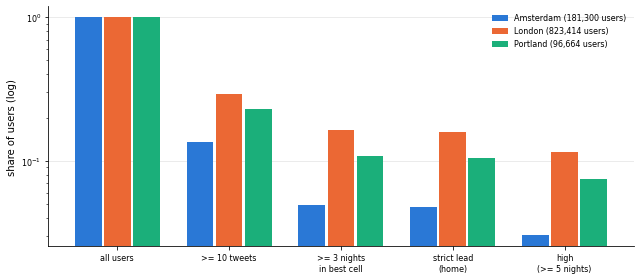

In [5]:
# ── plot: funnel as share of all users ────────────────────────────────────────
STEPS = ["n_users", "n_10_tweets", "n_3_nights", "n_home", "n_high"]
STEP_LABEL = ["all users", ">= 10 tweets", ">= 3 nights\nin best cell", "strict lead\n(home)", "high\n(>= 5 nights)"]

fig, ax = plt.subplots(figsize=(9, 4))
width = 0.26
x = np.arange(len(STEPS))
for i, city in enumerate(CITIES):
    share = funnel.loc[city, STEPS] / funnel.loc[city, "n_users"]
    ax.bar(x + (i - 1) * width, share, width=width * 0.92, color=CITY_COLOR[city],
           label=f"{CITY_LABEL[city]} ({funnel.loc[city, 'n_users']:,} users)")

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(STEP_LABEL, fontsize=FS2)
ax.set_ylabel("share of users (log)")
style_axis(ax)
ax.legend(frameon=False, fontsize=FS2)
plt.tight_layout()

## 1.3 Coverage by activity

Share of users with a res 9 home, by tweets in the city. Below 10 tweets: none by design.

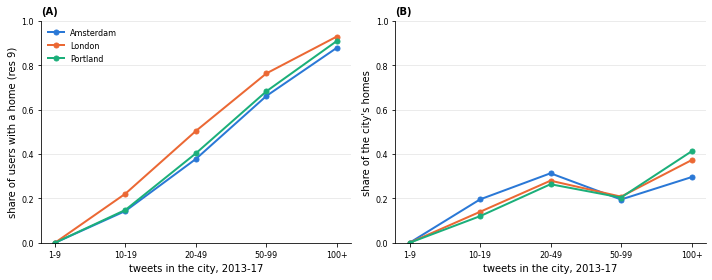

In [6]:
# ── users and res 9 homes by activity ─────────────────────────────────────────
coverage = pd.read_sql("""
select u.city
     , case
           when u.n_all < 10  then '1-9'
           when u.n_all < 20  then '10-19'
           when u.n_all < 50  then '20-49'
           when u.n_all < 100 then '50-99'
           else '100+'
       end                                              as tweets
     , count(*)                                         as n_users
     , count(h.user_id)                                 as n_homes
     , count(*) filter (where h.confidence = 'high')    as n_high
from revised.home_user u
left join revised.home_final h
  on h.city = u.city and h.user_id = u.user_id and h.res = 9
group by 1, 2
""", engine)

BUCKETS = ["1-9", "10-19", "20-49", "50-99", "100+"]
coverage["tweets"] = pd.Categorical(coverage["tweets"], categories=BUCKETS, ordered=True)
coverage = coverage.sort_values(["city", "tweets"])
coverage["share_home"] = coverage["n_homes"] / coverage["n_users"]

# ── plot: share with a home, and where the homes come from ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(BUCKETS))
for city in CITIES:
    sub = coverage[coverage["city"] == city]
    axes[0].plot(x, sub["share_home"], marker="o", markersize=5, linewidth=2,
                 color=CITY_COLOR[city], label=CITY_LABEL[city])
    axes[1].plot(x, sub["n_homes"] / sub["n_homes"].sum(), marker="o", markersize=5, linewidth=2,
                 color=CITY_COLOR[city], label=CITY_LABEL[city])

axes[0].set_ylabel("share of users with a home (res 9)")
axes[1].set_ylabel("share of the city's homes")
for ax, label in zip(axes, PANEL):
    ax.set_xticks(x)
    ax.set_xticklabels(BUCKETS)
    ax.set_xlabel("tweets in the city, 2013-17")
    ax.set_ylim(0, 1)
    style_axis(ax, label)
axes[0].legend(frameon=False, fontsize=FS2)
plt.tight_layout()

---
# 2. Maps
## 2.1 Homes per H3 cell: res 9, res 10, res 10 zoomed

Counts of Twitter homes, not residents (~1-2% of users, skewed to heavy users). Log colour scale, per panel.

In [7]:
# ── homes per cell, res 10 and 9 ──────────────────────────────────────────────
homes = read_hex("""
select city
     , res
     , cell
     , count(*)                                       as n_homes
     , count(*) filter (where confidence = 'high')    as n_high
from revised.home_final
group by city, res, cell
""")
homes.groupby(["city", "res"])["n_homes"].describe()

count      mean        std  min  25%  50%   75%    max
city      res                                                          
amsterdam 9     1486.0  5.818304   8.667636  1.0  1.0  3.0   7.0  109.0
          10    3886.0  2.078744   2.047059  1.0  1.0  1.0   2.0   39.0
london    9    14877.0  8.750017  12.210028  1.0  3.0  5.0  10.0  402.0
          10   51699.0  2.402232   2.713928  1.0  1.0  2.0   3.0   93.0
portland  9     3007.0  3.354506   5.460622  1.0  1.0  2.0   4.0  107.0
          10    5997.0  1.587627   1.910401  1.0  1.0  1.0   2.0   85.0

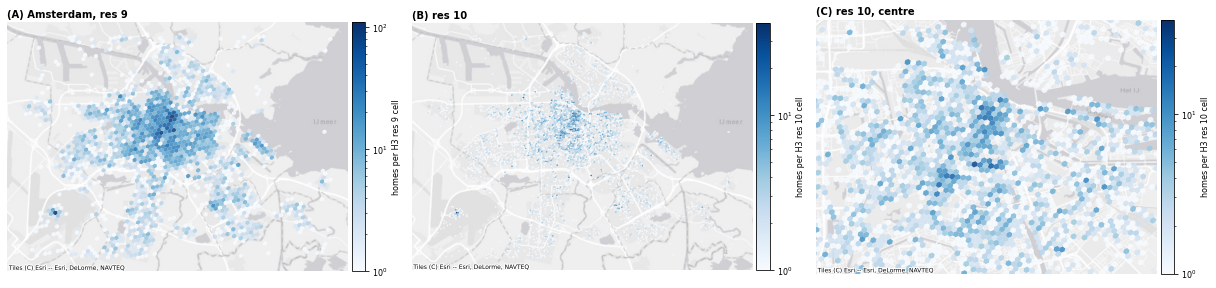

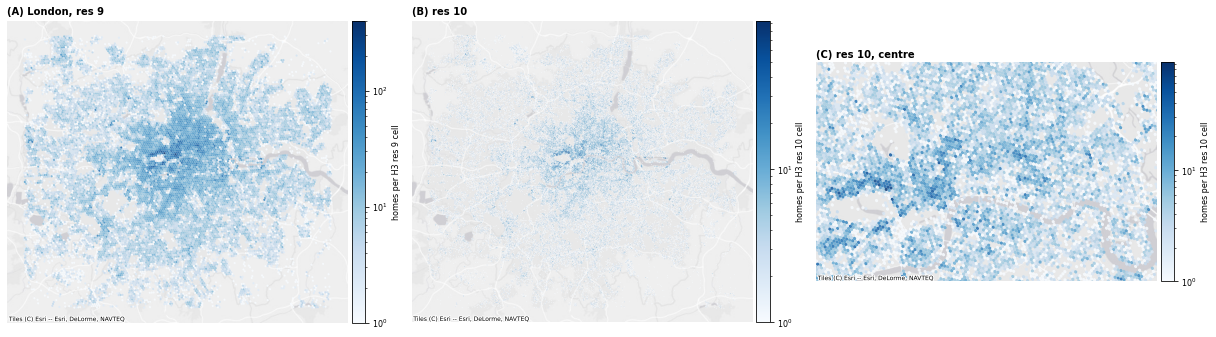

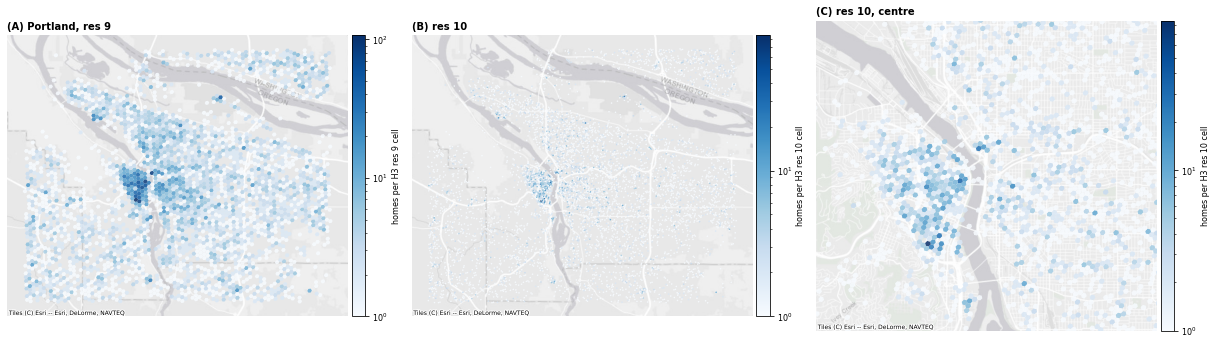

In [8]:
# ── plot: one figure per city ─────────────────────────────────────────────────
for city in CITIES:
    h9 = homes[(homes["city"] == city) & (homes["res"] == 9)]
    h10 = homes[(homes["city"] == city) & (homes["res"] == 10)]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
    hex_map(axes[0], h9, "n_homes", LogNorm(1, h9["n_homes"].max()),
            "homes per H3 res 9 cell", f"(A) {CITY_LABEL[city]}, res 9")
    hex_map(axes[1], h10, "n_homes", LogNorm(1, h10["n_homes"].max()),
            "homes per H3 res 10 cell", "(B) res 10")
    hex_map(axes[2], h10, "n_homes", LogNorm(1, h10["n_homes"].max()),
            "homes per H3 res 10 cell", "(C) res 10, centre", extent=zoom_extent(city))
    plt.tight_layout()

## 2.2 Homes relative to tweeting

Homes per 1,000 tweets in the cell (res 9, cells with >= 100 tweets). High values: residential areas;
low values: centres and hubs where many tweet but few live.

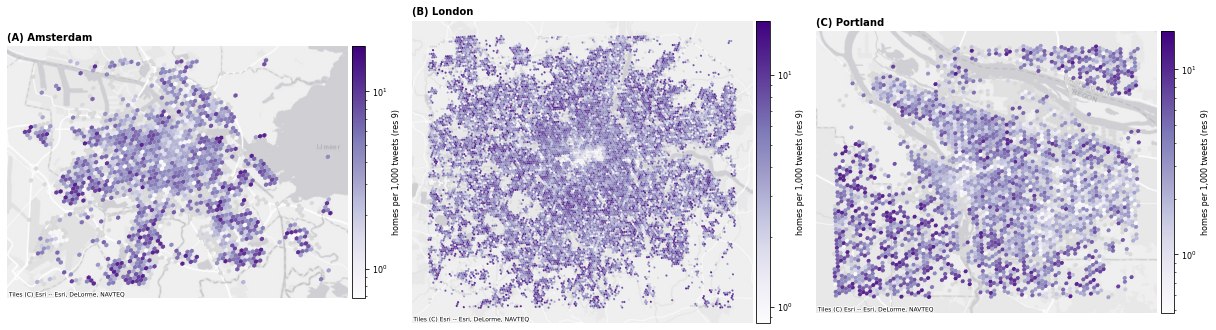

In [9]:
# ── homes and tweets per res 9 cell ───────────────────────────────────────────
rel_tw = read_hex("""
select t.city
     , t.cell
     , t.n_tweets
     , coalesce(h.n_homes, 0)    as n_homes
from (
    select city, cell, sum(n_all) as n_tweets
    from revised.home_user_cell
    where res = 9
    group by city, cell
) t
left join (
    select city, cell, count(*) as n_homes
    from revised.home_final
    where res = 9
    group by city, cell
) h
  on h.city = t.city and h.cell = t.cell
where t.n_tweets >= 100
""")
rel_tw["homes_per_1k_tweets"] = 1000 * rel_tw["n_homes"] / rel_tw["n_tweets"]

# ── plot: one map per city (cells without a home in grey) ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, city, label in zip(axes, CITIES, PANEL):
    sub = rel_tw[rel_tw["city"] == city]
    sub[sub["n_homes"] == 0].plot(color="0.85", linewidth=0, ax=ax)
    pos = sub[sub["n_homes"] > 0]
    norm = LogNorm(pos["homes_per_1k_tweets"].quantile(0.02), pos["homes_per_1k_tweets"].quantile(0.98))
    hex_map(ax, pos, "homes_per_1k_tweets", norm, "homes per 1,000 tweets (res 9)",
            f"{label} {CITY_LABEL[city]}", cmap="Purples")
plt.tight_layout()

## 2.3 Homes vs resident population

Population per H3 cell from a gridded census product (GHS-POP 2015; source, method and caveats in `external_data/population/README.md`).
Spearman correlation of homes and residents per cell, at res 8 (~0.7 km2), 9 and 10, and a map of homes per
1,000 residents. Res 10 population values are noisy (cell ~1.5 grid pixels).

Reads `external_data/population/pop_h3.csv` (columns `city, res, cell, pop`) from the repo root.

In [10]:
# ── population per H3 cell (CSV) ──────────────────────────────────────────────
POP_CSV = Path("../../../external_data/population/pop_h3.csv")
pop = pd.read_csv(POP_CSV, dtype={"cell": str})
pop.groupby(["city", "res"])["pop"].agg(["count", "sum"]).round(0)

count        sum
city      res                   
amsterdam 8       594  1005851.0
          9      3608  1006163.0
          10    19215  1006441.0
london    8      3960  9791703.0
          9     24348  9792037.0
          10   136689  9793300.0
portland  8       938  1059658.0
          9      5769  1056170.0
          10    33850  1055671.0

In [11]:
# ── homes per cell at res 8 / 9 / 10 (res 8 = parent of the res 9 home) ───────
homes_res = pd.read_sql("""
select city, 10 as res, cell::text as cell, count(*) as n_homes
from revised.home_final where res = 10 group by city, cell
union all
select city, 9 as res, cell::text as cell, count(*) as n_homes
from revised.home_final where res = 9 group by city, cell
union all
select city, 8 as res, public.h3_cell_to_parent(cell, 8)::text as cell, count(*) as n_homes
from revised.home_final where res = 9 group by city, 3
""", engine)

# ── join: every populated cell, homes 0 where none ────────────────────────────
hp = pop.merge(homes_res, on=["city", "res", "cell"], how="left").fillna({"n_homes": 0})
hp = hp[hp["pop"] > 0]

# ── Spearman correlation per city and res ─────────────────────────────────────
corr = (hp.groupby(["city", "res"])[["pop", "n_homes"]]
          .apply(lambda g: pd.Series({
              "n_cells": len(g),
              "spearman": spearmanr(g["pop"], g["n_homes"])[0],
              "homes_per_1k_pop": 1000 * g["n_homes"].sum() / g["pop"].sum(),
          }))
          .round(3))
corr

n_cells  spearman  homes_per_1k_pop
city      res                                      
amsterdam 8       594.0     0.819             8.567
          9      3608.0     0.710             8.537
          10    19215.0     0.461             7.658
london    8      3960.0     0.887            13.290
          9     24348.0     0.786            13.271
          10   136689.0     0.452            12.392
portland  8       938.0     0.646             9.362
          9      5769.0     0.525             9.266
          10    33842.0     0.257             8.076

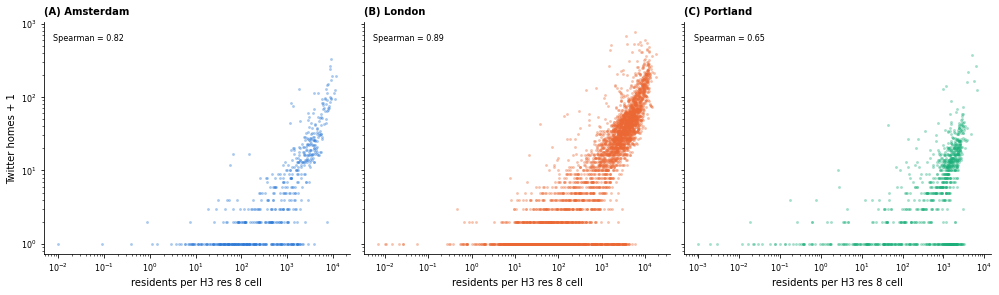

In [12]:
# ── plot: homes vs residents per res 8 cell ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, city, label in zip(axes, CITIES, PANEL):
    sub = hp[(hp["city"] == city) & (hp["res"] == 8)]
    ax.scatter(sub["pop"], sub["n_homes"] + 1, s=8, alpha=0.4, color=CITY_COLOR[city], linewidths=0)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("residents per H3 res 8 cell")
    rho = corr.loc[(city, 8), "spearman"]
    ax.text(0.03, 0.92, f"Spearman = {rho:.2f}", transform=ax.transAxes, fontsize=FS2)
    style_axis(ax, f"{label} {CITY_LABEL[city]}", grid=False)
axes[0].set_ylabel("Twitter homes + 1")
plt.tight_layout()

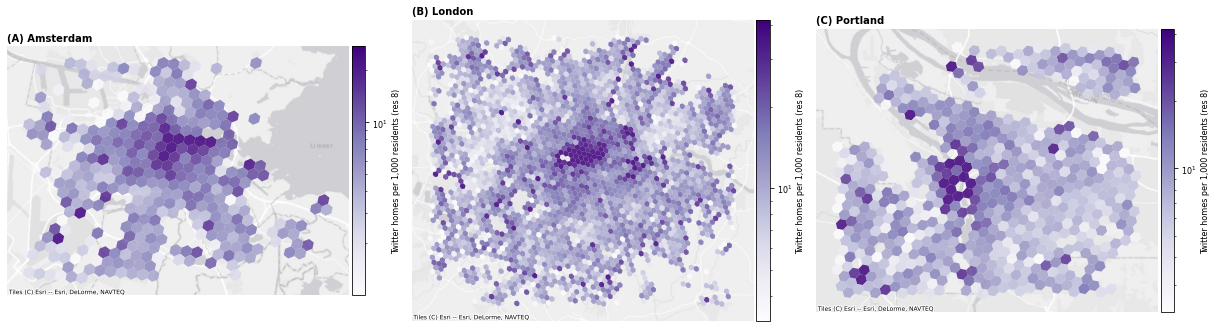

In [13]:
# ── map: homes per 1,000 residents, res 8 ─────────────────────────────────────
pen = hp[hp["res"] == 8].copy()
pen["homes_per_1k_pop"] = 1000 * pen["n_homes"] / pen["pop"]
pen = pen[(pen["pop"] >= 200) & (pen["n_homes"] > 0)]

geo = read_hex("""
select distinct public.h3_cell_to_parent(cell, 8) as cell
from revised.home_final
where res = 9
""")
pen = geo.merge(pen, on="cell")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, city, label in zip(axes, CITIES, PANEL):
    sub = pen[pen["city"] == city]
    norm = LogNorm(sub["homes_per_1k_pop"].quantile(0.02), sub["homes_per_1k_pop"].quantile(0.98))
    hex_map(ax, sub, "homes_per_1k_pop", norm, "Twitter homes per 1,000 residents (res 8)",
            f"{label} {CITY_LABEL[city]}", cmap="Purples")
plt.tight_layout()

---
# 3. Key rules
## 3.1 Night window (D02, D03)

Tweets by local hour. The 20:00-08:00 window (shaded) is the home signal; 22:00-07:00 is the sensitivity window.
Reads all of `home_input` (~44M rows): about a minute.

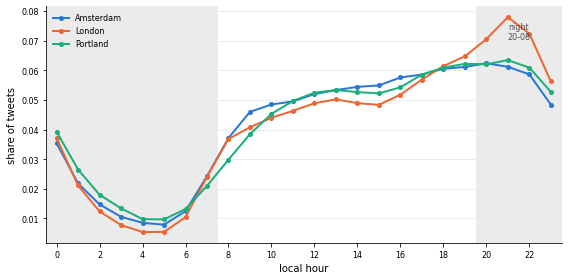

In [14]:
# ── tweets by local hour ──────────────────────────────────────────────────────
hours = pd.read_sql("""
select city
     , local_hour
     , count(*)    as n_tweets
from revised.home_input
group by city, local_hour
order by city, local_hour
""", engine)
hours["share"] = hours["n_tweets"] / hours.groupby("city")["n_tweets"].transform("sum")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(-0.5, 7.5, color="0.92", linewidth=0)
ax.axvspan(19.5, 23.5, color="0.92", linewidth=0)
for city in CITIES:
    sub = hours[hours["city"] == city]
    ax.plot(sub["local_hour"], sub["share"], marker="o", markersize=4, linewidth=2,
            color=CITY_COLOR[city], label=CITY_LABEL[city])
ax.text(21.5, 0.98 * hours["share"].max(), "night\n20-08", fontsize=FS2, color="0.3", ha="center", va="top")
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_xlabel("local hour")
ax.set_ylabel("share of tweets")
style_axis(ax)
ax.legend(frameon=False, fontsize=FS2, loc="upper left")
plt.tight_layout()

## 3.2 How a home is picked: one example user (D10, D15, D05)

A London user with a `high` home and a clear runner-up. Each res 10 cell where the user tweeted at night,
labelled with its number of distinct nights. The home is the cell with the most nights, and it must beat the
second cell strictly. Individual-level map: for internal use only, not for publication.

In [15]:
# ── pick a user: high home, runner-up with >= 5 nights, at least 3 nights behind ──
example = pd.read_sql("""
select user_id, cell::text as home_cell, d_home_nights, d_second_nights, n_user_tweets
from revised.home_final
where city = 'london'
  and res = 10
  and confidence = 'high'
  and d_second_nights >= 5
  and d_home_nights between d_second_nights + 3 and 40
order by user_id
limit 1
""", engine)
example

,user_id,home_cell,d_home_nights,d_second_nights,n_user_tweets
0,2659,8a194ad0264ffff,28,6,241


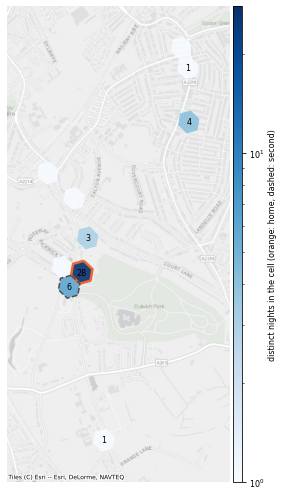

In [16]:
# ── the user's cells with night evidence ──────────────────────────────────────
uid = int(example.loc[0, "user_id"])
ucells = read_hex(f"""
select n.cell
     , n.d_night_20_08    as d_nights
     , c.n_all            as n_tweets
from revised.home_user_cell_nights n
join revised.home_user_cell c
  on c.city = n.city and c.user_id = n.user_id and c.res = n.res and c.cell = n.cell
where n.city = 'london'
  and n.user_id = {uid}
  and n.res = 10
  and n.d_night_20_08 >= 1
""")
ucells = ucells.sort_values("d_nights", ascending=False)

# ── keep cells within 3 km of the home so the map stays readable ──────────────
home_geom = ucells.geometry.iloc[0].centroid
near = ucells[ucells.geometry.centroid.distance(home_geom) <= 3000]

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))
norm = LogNorm(1, near["d_nights"].max())
near.plot(column="d_nights", cmap="Blues", norm=norm, linewidth=0, alpha=0.9, ax=ax)
near.iloc[[0]].boundary.plot(color="#eb6834", linewidth=2.5, ax=ax)
near.iloc[[1]].boundary.plot(color="0.3", linewidth=1.5, linestyle="--", ax=ax)
for _, r in near.head(6).iterrows():
    c = r["geometry"].centroid
    ax.text(c.x, c.y, str(r["d_nights"]), fontsize=FS2, ha="center", va="center")
pad = 300
xmin, ymin, xmax, ymax = near.total_bounds
ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution_size=FS4)
ax.set_axis_off()
cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.05)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Blues", norm=norm), cax=cax)
cb.set_label("distinct nights in the cell (orange: home, dashed: second)", fontsize=FS2)
cb.ax.tick_params(labelsize=FS2)
plt.tight_layout()

## 3.3 Nights vs the legacy ratio (D10)

Share of the user's nights that fall in the chosen home cell, res 9, 20-08. The legacy `ratio` method
(night / all tweets in a cell) tends to pick small, all-night cells; `nights` picks where the user spends
most nights.

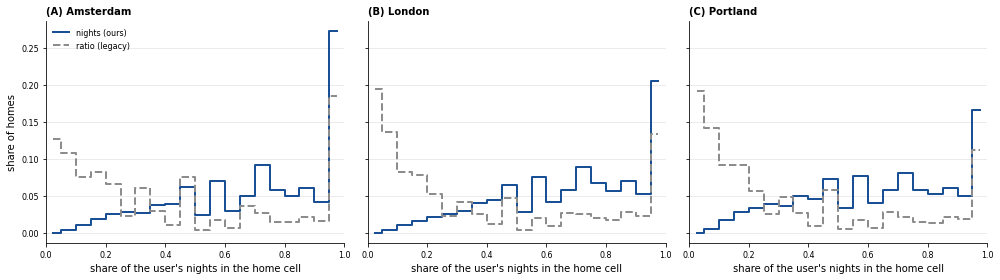

In [17]:
# ── share of the user's nights in the home: nights vs ratio ───────────────────
methods = pd.read_sql("""
select city
     , method
     , width_bucket(share_user_nights, 0, 1.000001, 20)    as bin
     , count(*)                                            as n_users
from revised.home_location
where night_window = '20-08'
  and res = 9
  and method in ('nights', 'ratio')
group by 1, 2, 3
""", engine)
methods["share"] = methods["n_users"] / methods.groupby(["city", "method"])["n_users"].transform("sum")
methods["x"] = (methods["bin"] - 0.5) / 20

# ── plot ──────────────────────────────────────────────────────────────────────
METHOD_STYLE = {
    "nights": {"color": "#184f95", "linestyle": "-",  "label": "nights (ours)"},
    "ratio":  {"color": "0.55",    "linestyle": "--", "label": "ratio (legacy)"},
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, city, label in zip(axes, CITIES, PANEL):
    for m, style in METHOD_STYLE.items():
        sub = methods[(methods["city"] == city) & (methods["method"] == m)].sort_values("x")
        ax.plot(sub["x"], sub["share"], linewidth=2, drawstyle="steps-mid", **style)
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of the user's nights in the home cell")
    style_axis(ax, f"{label} {CITY_LABEL[city]}")
axes[0].set_ylabel("share of homes")
axes[0].legend(frameon=False, fontsize=FS2, loc="upper left")
plt.tight_layout()

## 3.4 Gate and tiers (D05, D16)

Distinct nights in the home cell: every home has >= 3 (gate); `high` = >= 5.

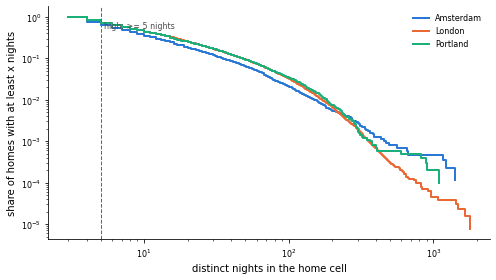

In [18]:
# ── home nights, res 9 ────────────────────────────────────────────────────────
ev = pd.read_sql("""
select city
     , d_home_nights
     , count(*)    as n_homes
from revised.home_final
where res = 9
group by city, d_home_nights
order by city, d_home_nights
""", engine)

# ── plot: share of homes with at least x nights ───────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
for city in CITIES:
    sub = ev[ev["city"] == city]
    ccdf = sub["n_homes"][::-1].cumsum()[::-1] / sub["n_homes"].sum()
    ax.step(sub["d_home_nights"], ccdf, where="post", linewidth=2,
            color=CITY_COLOR[city], label=CITY_LABEL[city])
ax.axvline(5, color="0.4", linestyle="--", linewidth=1)
ax.text(5.3, 0.55, "high: >= 5 nights", fontsize=FS2, color="0.3")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("distinct nights in the home cell")
ax.set_ylabel("share of homes with at least x nights")
style_axis(ax, grid=False)
ax.legend(frameon=False, fontsize=FS2)
plt.tight_layout()

## 3.5 Reliability: week split vs period split (05 V1, V8)

Homes detected separately in two halves of each user's data (res 10; strict lead and >= 10 tweets in both
halves), by the nights in the weaker half.
- **alternate weeks**: both halves span 2013-17, so moving house cannot make them differ -> reliability.
- **2013-15 vs 2016-17**: differences mix moves with noise.

Dotted line: the gate (3 nights).

split             period    weeks
city      nights                 
amsterdam 1-2      237.0   1200.0
          3-4      128.0   1038.0
          5-9      110.0   1084.0
          10-19     44.0    660.0
          20+       48.0    608.0
london    1-2     2566.0  16902.0
          3-4     1505.0  17386.0
          5-9     1229.0  20164.0
          10-19    544.0  13520.0
          20+      378.0  13213.0
portland  1-2      305.0   1420.0
          3-4      166.0   1309.0
          5-9      151.0   1545.0
          10-19     85.0   1045.0
          20+       73.0   1008.0

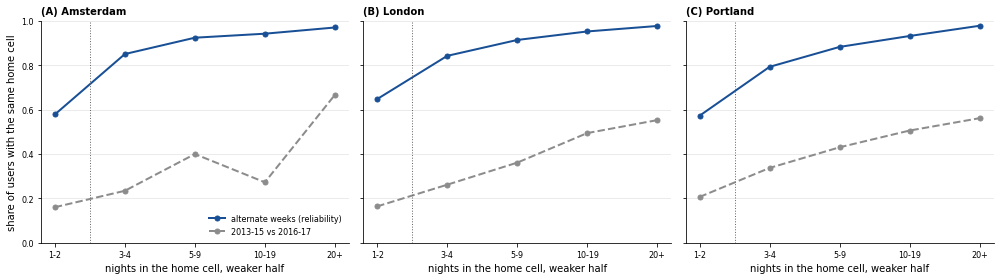

In [19]:
# ── same-cell agreement by split and night evidence ───────────────────────────
rel = pd.read_sql("""
with pair as (
    select case when a.period = '2013-15' then 'period' else 'weeks' end as split
         , a.city
         , least(a.d_night, b.d_night)    as d_min
         , a.cell = b.cell                as same
    from revised.home_diag_period_home a
    join revised.home_diag_period_home b
      on b.city = a.city and b.user_id = a.user_id and b.res = a.res
     and b.period = case a.period when '2013-15' then '2016-17' else 'wk-b' end
    where a.period in ('2013-15', 'wk-a')
      and a.res = 10
      and a.strict_lead and b.strict_lead
      and a.n_user_all >= 10 and b.n_user_all >= 10
)
select split
     , city
     , case
           when d_min <= 2  then '1-2'
           when d_min <= 4  then '3-4'
           when d_min <= 9  then '5-9'
           when d_min <= 19 then '10-19'
           else '20+'
       end                  as nights
     , count(*)             as n_users
     , avg(same::int)       as share_same
from pair
group by 1, 2, 3
""", engine)

NIGHTS = ["1-2", "3-4", "5-9", "10-19", "20+"]
rel["nights"] = pd.Categorical(rel["nights"], categories=NIGHTS, ordered=True)
rel = rel.sort_values(["split", "city", "nights"])

# ── plot: one panel per city ──────────────────────────────────────────────────
SPLIT_STYLE = {
    "weeks":  {"color": "#184f95", "linestyle": "-",  "label": "alternate weeks (reliability)"},
    "period": {"color": "0.55",    "linestyle": "--", "label": "2013-15 vs 2016-17"},
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, city, label in zip(axes, CITIES, PANEL):
    for split, style in SPLIT_STYLE.items():
        sub = rel[(rel["city"] == city) & (rel["split"] == split)]
        ax.plot(sub["nights"].cat.codes, sub["share_same"], marker="o", markersize=5, linewidth=2, **style)
    ax.axvline(0.5, color="0.4", linestyle=":", linewidth=1)
    ax.set_xticks(np.arange(len(NIGHTS)))
    ax.set_xticklabels(NIGHTS)
    ax.set_xlabel("nights in the home cell, weaker half")
    ax.set_ylim(0, 1)
    style_axis(ax, f"{label} {CITY_LABEL[city]}")
axes[0].set_ylabel("share of users with the same home cell")
axes[0].legend(frameon=False, fontsize=FS2, loc="lower right")
plt.tight_layout()

# ── users behind each point ───────────────────────────────────────────────────
rel.pivot_table(index=["city", "nights"], columns="split", values="n_users", observed=True)

## 3.6 Moves between periods (05 V7, `moved`)

Users whose 2013-15 and 2016-17 homes can both be detected (gated; 4-6% of homes), by distance between
the two homes (res 10). `moved` = >= 1 km.

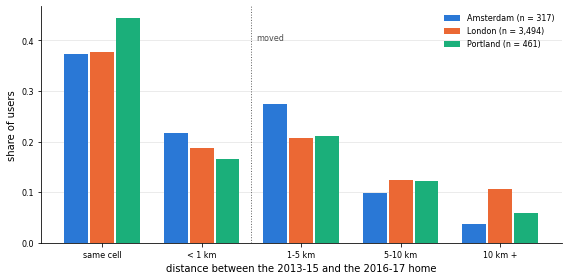

In [20]:
# ── distance between period homes ─────────────────────────────────────────────
mv = pd.read_sql("""
select city
     , case
           when period_dist_m = 0     then 'same cell'
           when period_dist_m < 1000  then '< 1 km'
           when period_dist_m < 5000  then '1-5 km'
           when period_dist_m < 10000 then '5-10 km'
           else '10 km +'
       end           as dist
     , count(*)      as n_users
from revised.home_final
where res = 10
  and period_dist_m is not null
group by 1, 2
""", engine)

DIST = ["same cell", "< 1 km", "1-5 km", "5-10 km", "10 km +"]
shares = mv.pivot(index="city", columns="dist", values="n_users").reindex(columns=DIST).fillna(0)
n_city = shares.sum(axis=1)
shares = shares.div(n_city, axis=0)

# ── plot: grouped bars ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.26
x = np.arange(len(DIST))
for i, city in enumerate(CITIES):
    ax.bar(x + (i - 1) * width, shares.loc[city], width=width * 0.92, color=CITY_COLOR[city],
           label=f"{CITY_LABEL[city]} (n = {int(n_city[city]):,})")
ax.axvline(1.5, color="0.4", linestyle=":", linewidth=1)
ax.text(1.55, 0.9 * shares.to_numpy().max(), "moved", fontsize=FS2, color="0.3")
ax.set_xticks(x)
ax.set_xticklabels(DIST)
ax.set_xlabel("distance between the 2013-15 and the 2016-17 home")
ax.set_ylabel("share of users")
style_axis(ax)
ax.legend(frameon=False, fontsize=FS2)
plt.tight_layout()